(10000, 4) 0 peak_load
0    0.8695
1    0.1305
Name: proportion, dtype: float64

=== Baseline (threshold=0.5) ===
Accuracy : 0.998
Precision: 1.0
Recall   : 0.985
F1       : 0.992
ROC-AUC  : 1.0
Confusion matrix:
 [[1739    0]
 [   4  257]]

=== Class-weighted (threshold=0.5) ===
Accuracy : 0.979
Precision: 0.861
Recall   : 1.0
F1       : 0.926
ROC-AUC  : 1.0
Confusion matrix:
 [[1697   42]
 [   0  261]]
Best F1 threshold: 0.789

=== Tuned threshold (threshold=0.7889384810389748) ===
Accuracy : 0.999
Precision: 1.0
Recall   : 0.992
F1       : 0.996
ROC-AUC  : 1.0
Confusion matrix:
 [[1739    0]
 [   2  259]]
       feature       coef    odds_ratio
0  temperature   5.794235  3.284010e+02
1     humidity   4.644339  1.039946e+02
2        usage  14.570843  2.128319e+06
Intercept: [-18.60007697]


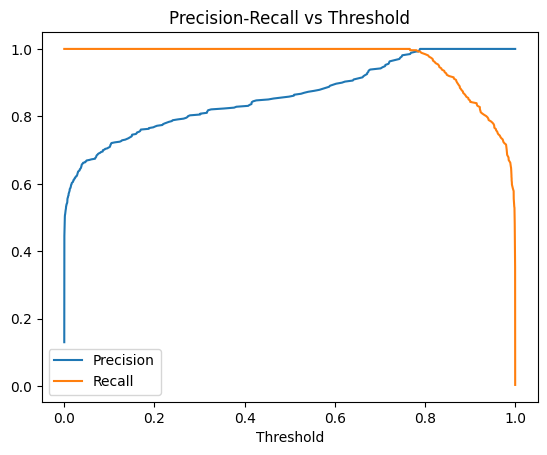

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, precision_recall_curve)

df = pd.read_csv("energy.csv")
print(df.shape, df.isna().sum().sum(), df["peak_load"].value_counts(normalize=True))
df = df.dropna().drop_duplicates()

X = df[["temperature", "humidity", "usage"]]; y = df["peak_load"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

def fit_eval(class_weight=None, threshold=0.5, label=""):
    m = Pipeline([("sc", StandardScaler()),
                  ("lr", LogisticRegression(class_weight=class_weight, max_iter=1000))])
    m.fit(X_train, y_train)
    proba = m.predict_proba(X_test)[:, 1]
    pred = (proba >= threshold).astype(int)
    print(f"\n=== {label} (threshold={threshold}) ===")
    print("Accuracy :", round(accuracy_score(y_test, pred), 3))
    print("Precision:", round(precision_score(y_test, pred, zero_division=0), 3))
    print("Recall   :", round(recall_score(y_test, pred), 3))
    print("F1       :", round(f1_score(y_test, pred), 3))
    print("ROC-AUC  :", round(roc_auc_score(y_test, proba), 3))
    print("Confusion matrix:\n", confusion_matrix(y_test, pred))
    return m, proba

m1, p1 = fit_eval(None, 0.5, "Baseline")
m2, p2 = fit_eval("balanced", 0.5, "Class-weighted")

# Threshold tuning: best F1 on the weighted model
prec, rec, thr = precision_recall_curve(y_test, p2)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
best = thr[np.argmax(f1s[:-1])]
print("Best F1 threshold:", round(best, 3))
m3, p3 = fit_eval("balanced", best, "Tuned threshold")

lr = m2.named_steps["lr"]
coef = pd.DataFrame({"feature": X.columns, "coef": lr.coef_[0], "odds_ratio": np.exp(lr.coef_[0])})
print(coef); print("Intercept:", lr.intercept_)

plt.plot(thr, prec[:-1], label="Precision"); plt.plot(thr, rec[:-1], label="Recall")
plt.xlabel("Threshold"); plt.legend(); plt.title("Precision-Recall vs Threshold"); plt.show()
